# Q1B | Display the Statistical Values

> B. Display the statistical values for each of the attributes, along with visualizations (e.g., histogram) of the distributions for each attribute. Explain noticeable traits for key attributes. Are there any attributes that might require special treatment? If so, what special treatment might they require?

**IMPORTANT**
This notebook uses only the train dataset, so no analysis or treatment decision is influenced by the test data (data snooping).

# Answer Summary

**Statistics and visualizations**
- Each attribute has a statistics table (center, spread, skew, kurtosis, IQR outliers, correlation with `Life Ladder`) and five plots: histogram, QQ plot, box plot, a scatter against `Life Ladder` (linear, LOWESS and the best candidate shapes), and a chart of every candidate shape's R² gain over the linear fit. The target has the table, histogram and QQ plot.

**Noticeable traits**
- Target: roughly symmetric, with no missing values and no IQR outliers.
- Strength of the relationship with `Life Ladder`: strong for `Log GDP per capita`, `Healthy life expectancy at birth` and `Social support`. Moderate for `Positive affect`, `Freedom to make life choices` and `Perceptions of corruption`. Weak for `Negative affect` and `Generosity`.
- Shape: `Social support`, `Healthy life expectancy at birth` and `Freedom to make life choices` are shallow at the low end and steep at the top, so the straight line under-predicts both ends, and their best shape gains +0.04 to +0.07 in R².
- `Generosity` is a level shift, not a slope: a single 0 / 1 flag reaches LOWESS.
- `Log GDP per capita` and `Negative affect` bend only a little, and `Perceptions of corruption` and `Positive affect` are already straight (their best shape gains about 0.01).
- Outliers sit on the trend: the low tails of `Perceptions of corruption`, `Social support`, `Healthy life expectancy at birth` and `Freedom to make life choices`, and the high tail of `Negative affect`, follow LOWESS. The high tail of `Generosity` is the one place where LOWESS runs opposite to the straight line: LOWESS drifts down while the line keeps rising.
- Scale: `Healthy life expectancy at birth` has a std of 7.478, against under 0.2 for six of the other seven attributes.

**Special treatment**
- Feature engineering: recommend a hinge on `Social support` and `Freedom to make life choices`, a floor or a hinge on `Healthy life expectancy at birth`, and a high generosity flag (a 0 / 1 step) in place of raw `Generosity`: each gains +0.03 to +0.07 in R². Worth testing, small gain: a hinge on `Log GDP per capita` and `Negative affect`. Avoid every shape on `Perceptions of corruption` (including a low corruption flag) and `Positive affect`, and a 0 / 1 flag (step) on every attribute except `Generosity`: it loses R² on six of the eight attributes.
- Transformations: recommend a one column alternative to the hinge: a re-expression that is steep at the high end on `Social support` and `Freedom to make life choices` (the reflected reciprocal), and on `Healthy life expectancy at birth` Yeo-Johnson, or winsorize (a piecewise linear clip). Avoid every re-expression on the other five attributes (gain +0.01 or less), whatever their skew.
- Scaling: standardize: the std runs from under 0.2 (six of the attributes) up to 7.478 (`Healthy life expectancy at birth`).
- Imputation: fill with the median: six of the eight attributes are skewed, and on the other two the mean and median are close. A 0 / 1 missing flag is worth testing on `Perceptions of corruption` (86 rows) and `Generosity` (71 rows).
- Dropping: test the model without `Generosity` and `Negative affect`: even LOWESS reaches only R² 0.07 and 0.11.
- Outliers: do not clip or drop: every outlier tail sits on LOWESS. On the high tail of `Generosity` the straight line keeps rising while LOWESS drifts down, but the generosity flag already handles it.
- None: `Life Ladder`: no transform (log or square root), as it is already roughly symmetric (skew 0.075).

---

# Imports

In [1]:
import pandas as pd

import Q1.consts as Q1_CONSTS

from utils import (
	read_csv_to_df,
	STATISTICS,
	PLOTTING,
)

pd.set_option('display.max_rows', None)
pd.set_option('display.min_rows', None)
pd.set_option('display.max_columns', None)

# Fetch Data

In [2]:
train_df = read_csv_to_df(path=Q1_CONSTS.TRAIN_PATH)

# Statistical Values: Continuous Attributes

## How to Read the Plots

- **Statistics table:** the skew RoT row reads a skew between -0.5 and 0.5 as roughly symmetric, 0.5 to 1 either way as moderately skewed, and beyond 1 as highly skewed. The notes call an attribute skewed when it is moderately or highly skewed. The kurtosis RoT row reads an excess kurtosis below -1 as light tails (platykurtic), -1 to 1 as near-normal tails (mesokurtic), 1 to 7 as heavy tails (leptokurtic) and above 7 as very heavy tails.
- **Strength labels** (in the notes): graded on the straight line's R² in the scatter legend. Under 0.01 is none, 0.01 to 0.16 weak, 0.16 to 0.49 moderate, 0.49 or more strong: the squares of the |r| cutoffs 0.1, 0.4 and 0.7 from Schober, Boer and Schwarte (2018), as Ferguson (2009) does.
- **Histogram w/ normal overlay:** the attribute's distribution against a normal curve with the same mean and SD. The orange and green lines mark the mean and the median, and the gray lines mark 1, 2 and 3 SDs from the mean. Gaps between the bars and the red curve show skew, values piling up at one end, or more than one peak.
- **QQ plot:** the sorted values against the values a normal distribution would produce. Points on the red line mean normal.
  - Low end below the line and high end above it: heavy tails. The reverse: light tails.
  - Points bowing above the line through the middle: left skew. Bowing below: right skew.
  - A flat run at one end: values piling up against a limit.
- **Box plot:** the box spans the middle half of the values (Q1 to Q3), with the median as the green line and the mean as the orange diamond. The whiskers reach the furthest values inside the IQR fences, and the dots past them are the IQR outliers counted in the statistics table. A mean far from the median points to skew.
- **Scatter plot + candidate shapes:**
  - **Scatter plot** (R² in the legend):
    - Linear: the straight line on the raw attribute, the only shape the raw attribute gives a linear regression. Its R² is the bar every candidate shape has to beat.
    - LOWESS: a smoothed local trend with no fixed shape. Where it bends away from the linear fit, the raw attribute misfits. It hints at the shape to aim for, and its R² hints at how much a better shape could gain.
    - Candidate shapes: the best shape of each family, drawn in the family's color only when it beats the linear R² by 0.01 or more.
  - **Candidate shapes chart**: each bar is a shape's R² gain over the linear fit (red line at 0), highest R² on top. The dashed green line marks LOWESS. The label gives the shape's R², its gain, and how many columns it uses (more columns always fit a little better). The x axis is scaled to each chart's own gains, so a gain of 0.01 can draw as a long bar: compare the numbers, not the bar lengths.
  - **How every candidate is fitted**: each shape rebuilds the attribute as one or more new columns, then fits an ordinary linear regression of `Life Ladder` on those columns. Only the attribute is changed, never `Life Ladder`. Each is graded by its R² on the train rows.
  - **How a setting is searched**: a shape with a setting (a threshold, shift, power or clip point) is fitted once for every value in a fixed list, and the value with the highest R² is kept. The search sees the same rows it is scored on, so those R² values are optimistic. A gain of 0.01 to 0.02 over the linear R² is not evidence on its own.
  - **Tiers** (R² gain over the linear fit, rounded to 2 decimals): 0.03 or more, recommend; 0.02, worth testing, small gain; 0.01 or less, avoid.

**Re-expression family**: replace the attribute with one new column, a bent version of it. The fit is a straight line on the new scale, which draws as a smooth curve on the original one. It targets a LOWESS curve that bends gradually and in the same direction across the whole range.

| Shape | Goal | What it does to the attribute | Setting and how it is set |
| --- | --- | --- | --- |
| log | Follow a curve that is steep at one end and flattens toward the other, with the steep end at either the low or the high end. | As it is, `log(x + shift)` spreads the low values apart and squeezes the high values together, for a curve that is steep at the low end. Reflected, `log(shift - x)` does the mirror image, for a curve that is steep at the high end. | Direction (as it is or reflected) and shift, searched together. For each direction, the shifts put the value at the steep end (the smallest value, or the largest when reflected) 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3 or 10 times the attribute's range above 0. The closer to 0, the harder the bend; the furthest is close to a straight line. As it is, no shift at all is also tried when every value is above 0. Best R² kept. |
| sqrt | The same as log, with a milder bend. | `sqrt(x + shift)`, or reflected `sqrt(shift - x)`: like log, with less stretching at the steep end. | Direction and shift: the same lists as log, plus the steep end placed exactly at 0. |
| reciprocal | The same as log, with the sharpest bend of the three. | `1 / (x + shift)`, or reflected `1 / (shift - x)`: like log, with more stretching at the steep end. It also reverses the order of the values, which the fitted slope reverses back. | Direction and shift: the same lists as log. |
| Yeo-Johnson | Follow a gradual bend in either direction. | A power transform with power λ: λ = 1 leaves the attribute as it is, λ below 1 squeezes the high values (like log), and λ above 1 squeezes the low values, for a curve that is flat at the low end and steep at the high end. It works on 0 and negative values without a shift. | λ: -10 to 30 in steps of 0.5. Best R² kept. |

Log, sqrt and reciprocal are Box-Cox at the powers 0, 0.5 and -1. A straight line fits Box-Cox exactly as well as the plain transform, so Box-Cox is not repeated as its own shape.

Yeo-Johnson has no reflected version: flipping the sign of the attribute gives exactly the fit of Yeo-Johnson at the power 2 - λ, so its powers above 1 already cover the mirror image.

**Piecewise linear family**: straight segments joined at a threshold `t`, so the line can change slope or go flat at one point. It targets a LOWESS curve with a corner, or one that goes flat past some value.

| Shape | Goal | What it does to the attribute | Setting and how it is set |
| --- | --- | --- | --- |
| hinge | Let the slope change at `t`. | Keeps the attribute and adds a second column `max(0, x - t)`, how far the value is past `t` (0 below it). The fit gets one slope below `t` and another above it, joined at `t`. 2 columns. | `t`: every distinct value of the attribute that leaves at least 5% of the rows on each side. Best R² kept. |
| cap | The attribute stops mattering above `t`. | `min(x, t)`: every value above `t` becomes `t`, so the line is flat past it. | `t`: the same search as the hinge. |
| floor | The attribute only starts mattering above `t`. | `max(x, t)`: every value below `t` becomes `t`, so the line is flat before it. | `t`: the same search as the hinge. |
| winsorize | Stop the most extreme values on both ends from pulling the line. | Every value below the p-th percentile becomes the p-th percentile, and every value above the (100 - p)-th becomes the (100 - p)-th. The line is flat past both clip points. | p: 1% to 45% in steps of 1 (45% leaves only the middle 10% as it is). Best R² kept. |

**Bins family**: replace the attribute with groups, and predict each group with its own `Life Ladder` mean, a staircase. It targets a `Life Ladder` that jumps between levels instead of changing smoothly.

| Shape | Goal | What it does to the attribute | Setting and how it is set |
| --- | --- | --- | --- |
| step | One `Life Ladder` level below `t` and another at or above it. | A single 0 / 1 column: 1 when the value is at or above `t`, 0 below it. | `t`: the same search as the hinge. |
| quantile bins | Several levels across the range. | Cuts the attribute into 5 groups with the same number of rows each, one 0 / 1 column per group. One group is the baseline the intercept covers, so 4 columns. | Not searched: 5 bins is fixed, because more bins always fit the train rows a little better, so a search would always pick the most bins tried. |

# Life Ladder (TARGET)

In [3]:
STATISTICS.continuous_statistics_df(series=train_df[Q1_CONSTS.TARGET])

,Life Ladder
count,1559
missing,0
% missing,0.0
mean,5.469
std,1.113
min,2.375
50%,5.374
max,8.019
range,5.644
skew,0.075


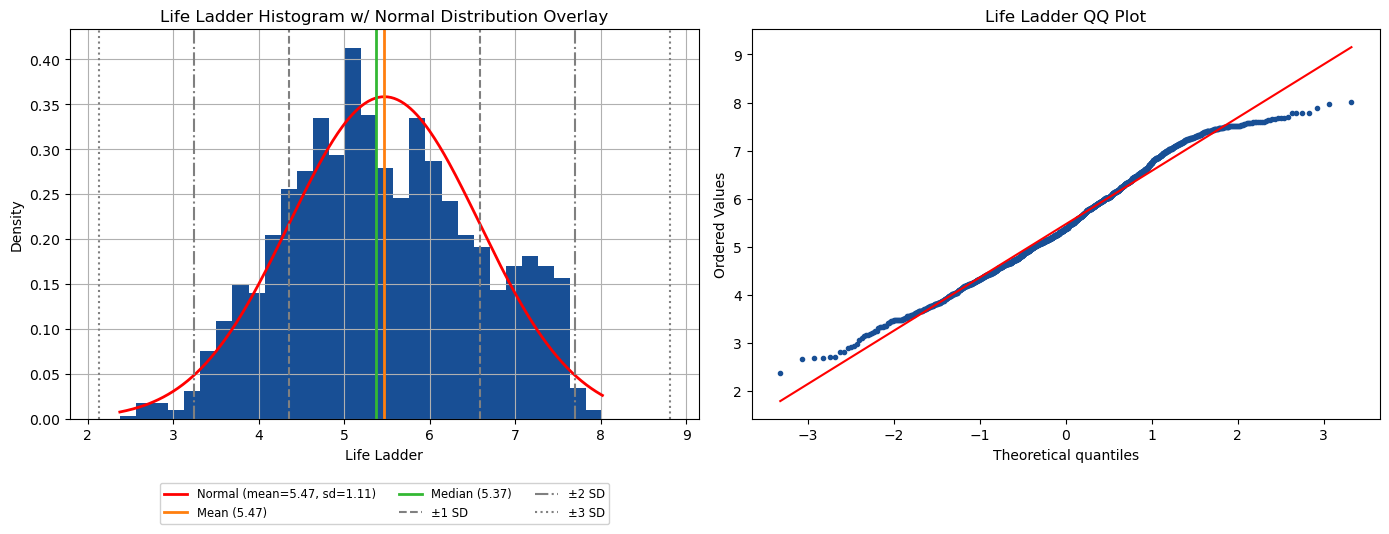

In [4]:
PLOTTING.continuous_distribution_plots(series=train_df[Q1_CONSTS.TARGET]);

## Notes / Observations

### Noticeable Traits / Key Attributes

- Roughly symmetric with near-normal tails (excess kurtosis -0.67): there is no long tail of extreme labels to pull the fit.
- No missing values and no IQR outliers: every train row has a usable label.

### Special Treatment

- None: no transform (log or square root): `Life Ladder` is already roughly symmetric (skew 0.075), so either would only skew it and force every prediction to be converted back.

# Perceptions of Corruption

In [5]:
STATISTICS.continuous_statistics_df(series=train_df[Q1_CONSTS.COLUMNS['POC']['col']], target=train_df[Q1_CONSTS.TARGET])

,Perceptions of corruption
count,1473
missing,86
% missing,5.516
mean,0.748
std,0.187
min,0.035
50%,0.804
max,0.983
range,0.948
skew,-1.536


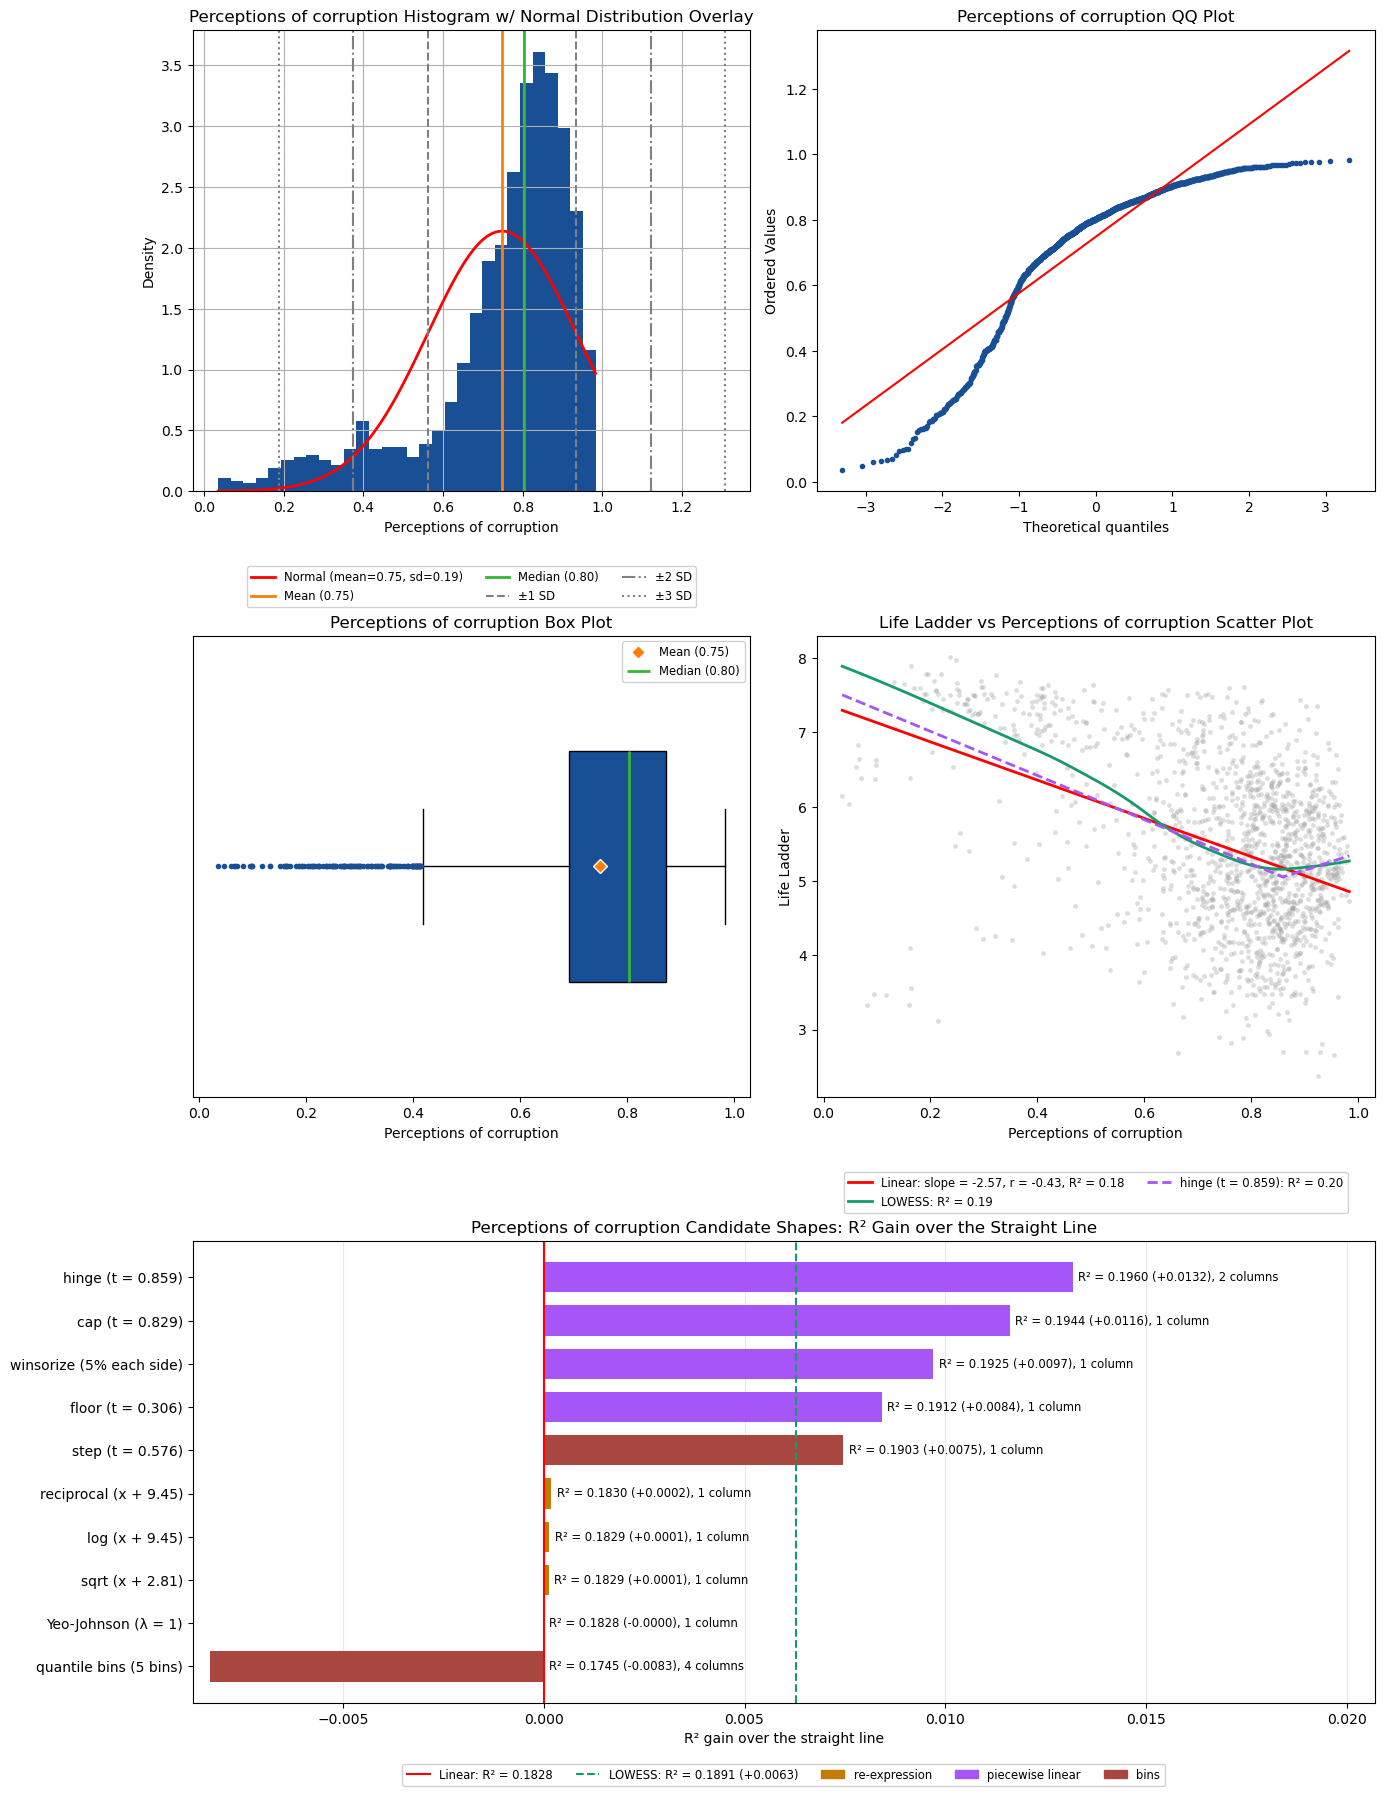

In [6]:
PLOTTING.continuous_single_feature_plots(df=train_df, feature=Q1_CONSTS.COLUMNS['POC']['col'], target=Q1_CONSTS.TARGET);

## Notes / Observations

### Noticeable Traits / Key Attributes

- The straight line already captures almost all of the shape: even LOWESS beats it by only 0.01 in R², so no reshaping of this column can move its predictions much.
- The signal is in the low tail: LOWESS is flat above about 0.8, where half the rows sit (median 0.804), so the column says little among them.
- The 130 low IQR outliers are on the trend: LOWESS is at its highest there and keeps falling through them, and the straight line runs below LOWESS, so it under-predicts them on average.
- 86 rows are missing, and the left skew pulls the mean below the median, so the fill value matters more here.

### Special Treatment

- **Feature engineering:** keep the raw value and avoid every piecewise and bins shape, including a low corruption flag (step): the best, the hinge, gains only +0.01, and LOWESS keeps falling on both sides of the step's cut.
- **Transformations:** avoid the whole re-expression family and winsorize: none gains more than +0.01.
- **Outliers:** keep the 130 low outliers, do not clip or drop them: they sit on the falling part of LOWESS.
- **Imputation:** fill the missing rows with the median, not the mean, which the low tail pulls down (0.804 against 0.748). A 0 / 1 missing flag is worth testing: the median puts every missing row on the flat part, where this column barely changes the prediction.

# Social Support

In [7]:
STATISTICS.continuous_statistics_df(series=train_df[Q1_CONSTS.COLUMNS['SS']['col']], target=train_df[Q1_CONSTS.TARGET])

,Social support
count,1549
missing,10
% missing,0.641
mean,0.813
std,0.119
min,0.29
50%,0.835
max,0.987
range,0.697
skew,-1.138


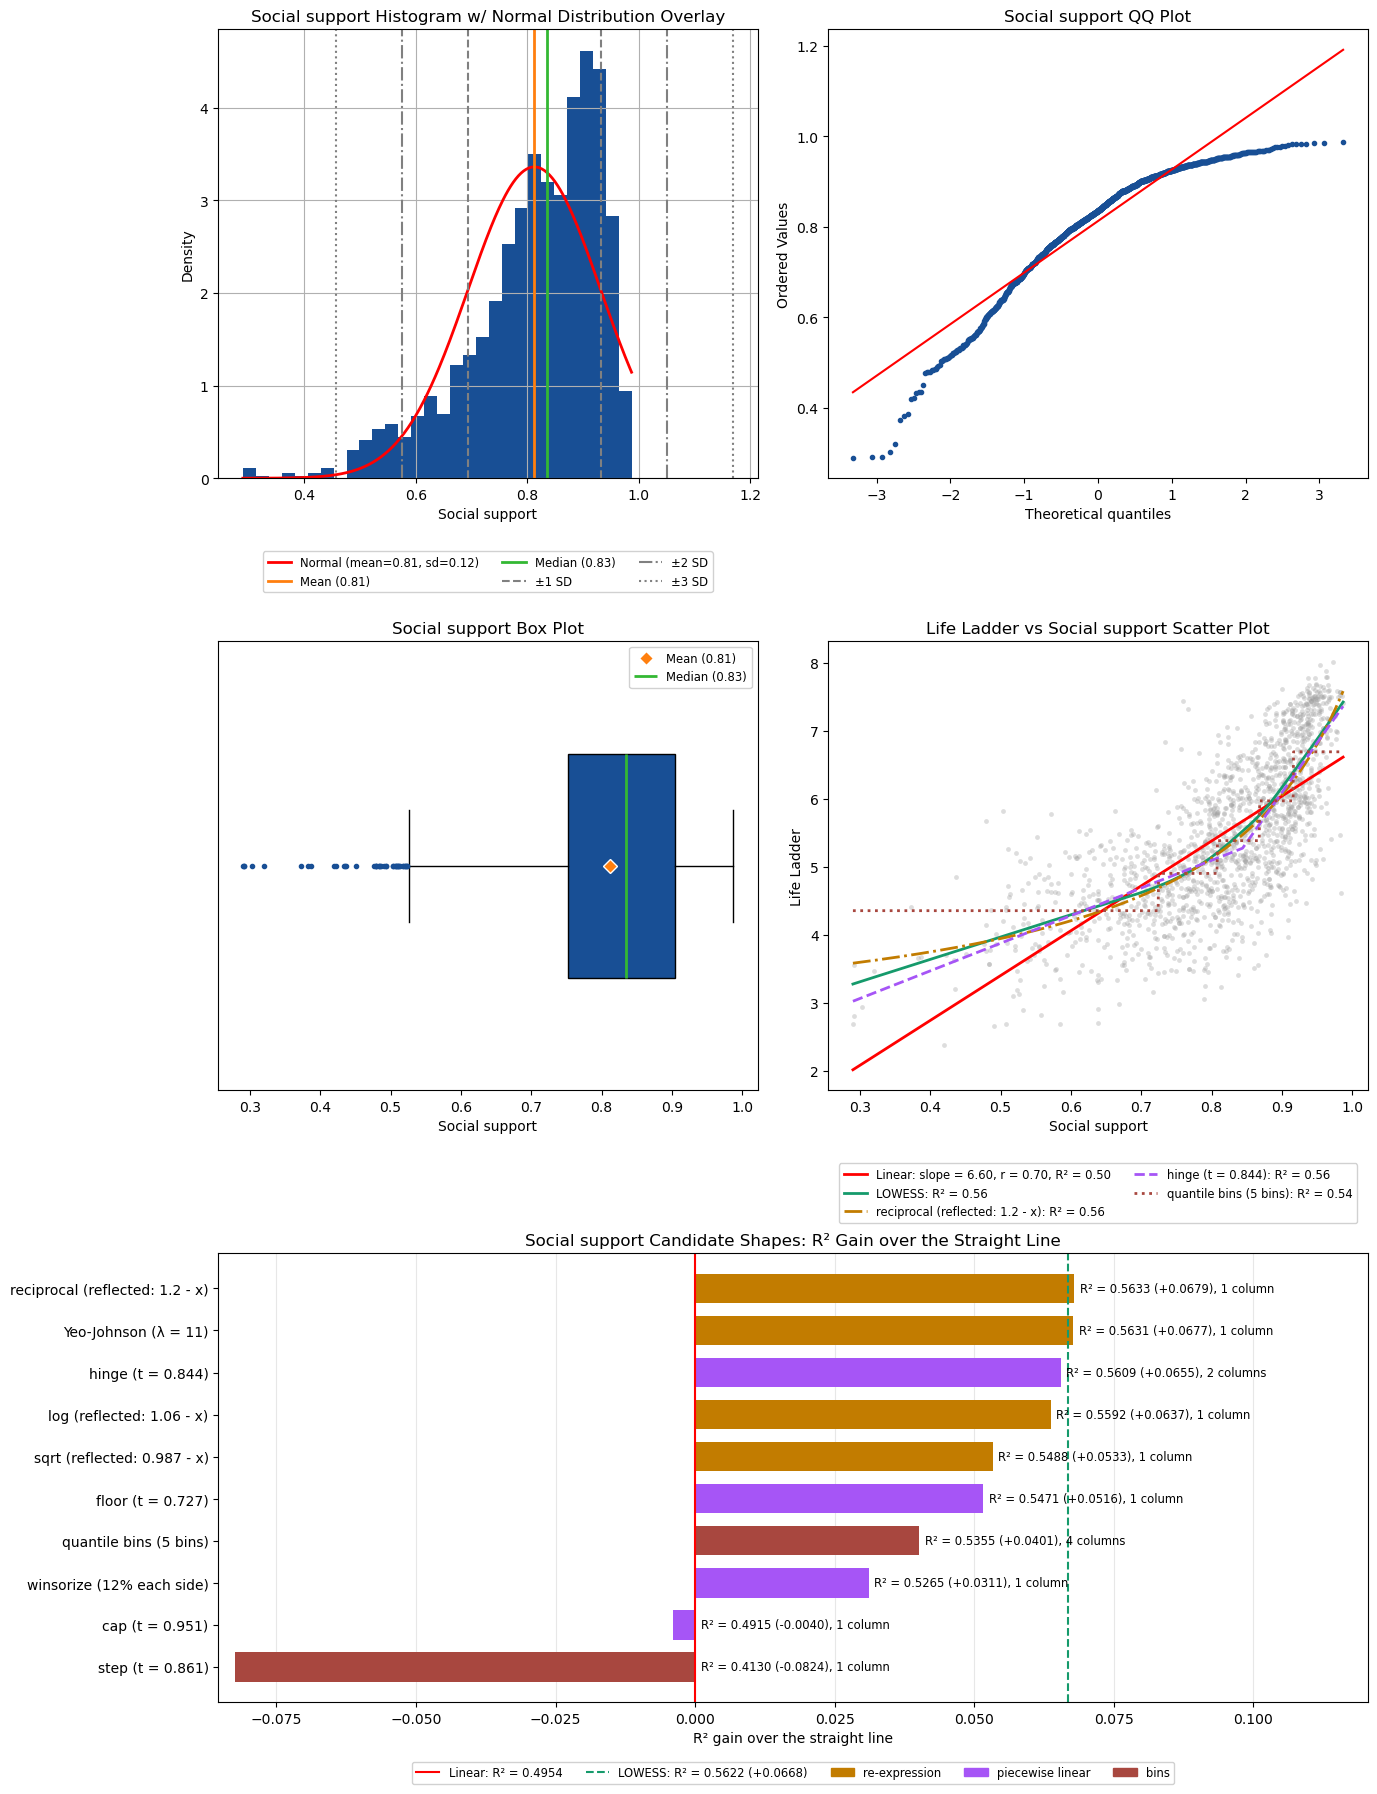

In [8]:
PLOTTING.continuous_single_feature_plots(df=train_df, feature=Q1_CONSTS.COLUMNS['SS']['col'], target=Q1_CONSTS.TARGET);

## Notes / Observations

### Noticeable Traits / Key Attributes

- Shallow, then steep: the straight line under-predicts `Life Ladder` at both ends and over-predicts in the middle, which costs R² 0.50 against 0.56 for LOWESS.
- The bend is gradual: one column re-expressions that bend hardest at the top fit as well as the two column hinge (R² 0.56 each), so the hinge's second column adds no fit over them.
- The 42 low IQR outliers follow the shallow part of LOWESS, so the misfit at the low end comes from the straight line, not from the outliers.

### Special Treatment

- **Feature engineering:** recommend the hinge at t = 0.844 (+0.07). The floor and quantile bins also reach the 0.03 tier, with less gain. Avoid the step and the cap: both lose R², because both flatten the top, where `Life Ladder` rises fastest.
- **Transformations:** recommend a re-expression that is steep at the high end, the reflected reciprocal or Yeo-Johnson: one column, level with LOWESS (+0.07 each). The reflected log and sqrt also reach the 0.03 tier. Winsorize reaches it too, but ranks last of them, and it clips the low tail that LOWESS runs through.
- **Outliers:** keep the 42 low outliers, do not drop them: LOWESS and the best shapes run through them.
- **Imputation:** fill the missing rows with the median: the left skew pulls the mean down (0.813 against the median 0.835).

# Generosity

In [9]:
STATISTICS.continuous_statistics_df(series=train_df[Q1_CONSTS.COLUMNS['G']['col']], target=train_df[Q1_CONSTS.TARGET])

,Generosity
count,1488
missing,71
% missing,4.554
mean,0.0
std,0.163
min,-0.335
50%,-0.025
max,0.698
range,1.033
skew,0.828


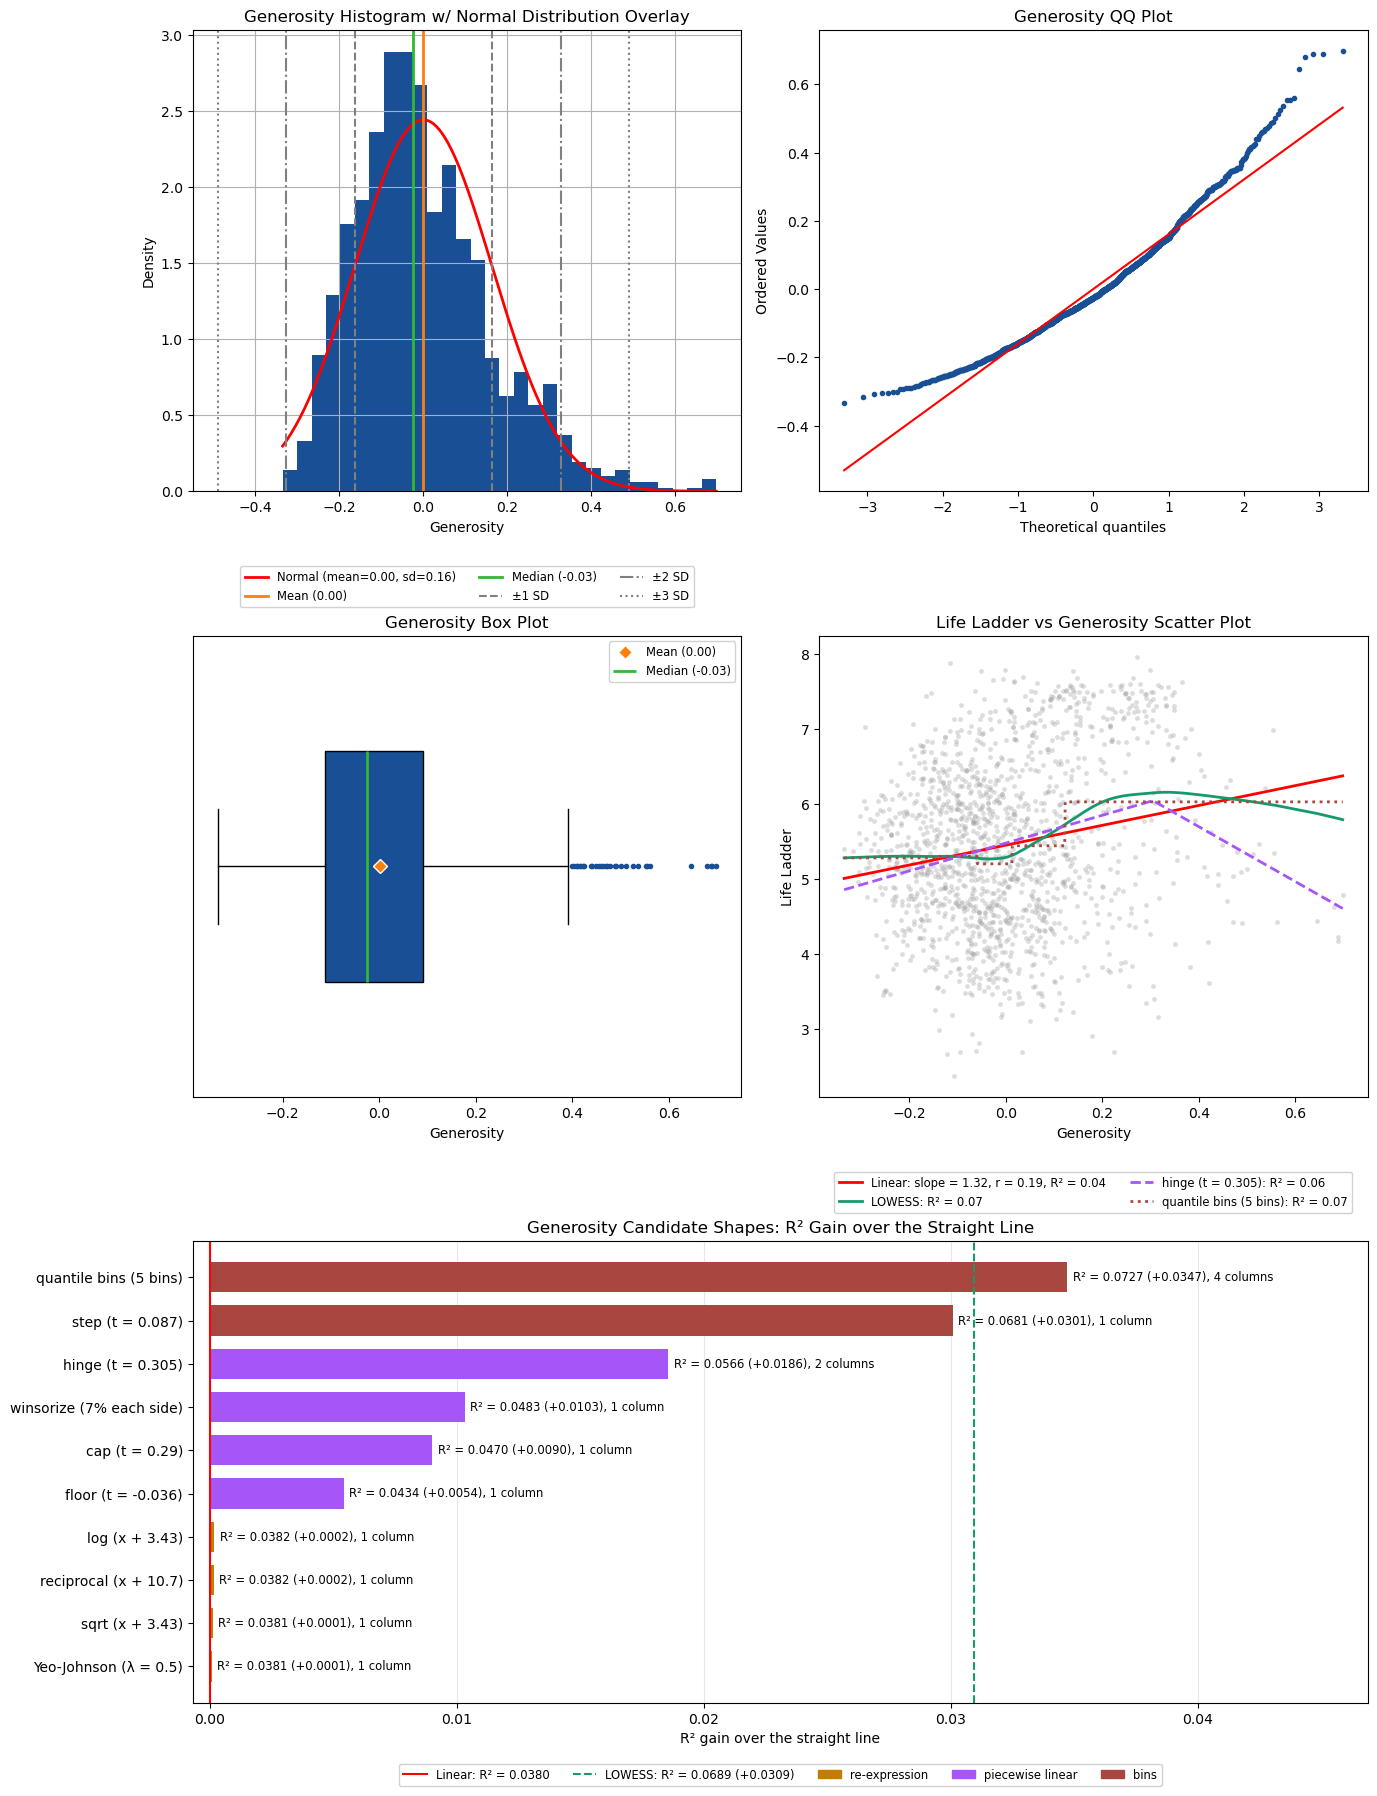

In [10]:
PLOTTING.continuous_single_feature_plots(df=train_df, feature=Q1_CONSTS.COLUMNS['G']['col'], target=Q1_CONSTS.TARGET);

## Notes / Observations

### Noticeable Traits / Key Attributes

- Weak in any shape: even LOWESS explains only R² 0.07 of `Life Ladder`, so this column can move the predictions only a little.
- The signal is a level shift, not a slope: LOWESS is flat at the low end, rises to a higher level, then drifts down. A single 0 / 1 flag reaches LOWESS (R² 0.07 each), while the straight line keeps rising where LOWESS does not.
- The 31 high IQR outliers sit off the straight line: LOWESS drifts down through them while the line keeps rising, so the line over-predicts them.
- 71 rows are missing, so the fill value decides the flag for a sizable group of rows.

### Special Treatment

- **Dropping:** test the model without it: even LOWESS only reaches R² 0.07.
- **Feature engineering:** if kept, replace the raw value with a high generosity flag, the step at t = 0.087 (1 at or above it, 0 below; +0.03). Quantile bins gain about the same with four columns instead of one, so the flag is the better choice. The hinge is worth testing, small gain (+0.02). Avoid the cap and the floor, which gain less.
- **Transformations:** avoid the whole re-expression family and winsorize: none gains more than +0.01.
- **Outliers:** do not clip the 31 high outliers as a separate step: the flag already gives them the same value as every other high generosity row.
- **Imputation:** if kept, fill the missing rows with the median (-0.025), which puts them all on the low side of the flag. A 0 / 1 missing flag is worth testing with this many missing rows.

# Healthy Life Expectancy at Birth

In [11]:
STATISTICS.continuous_statistics_df(series=train_df[Q1_CONSTS.COLUMNS['HLEAB']['col']], target=train_df[Q1_CONSTS.TARGET])

,Healthy life expectancy at birth
count,1522
missing,37
% missing,2.373
mean,63.332
std,7.478
min,32.3
50%,65.18
max,77.1
range,44.8
skew,-0.723


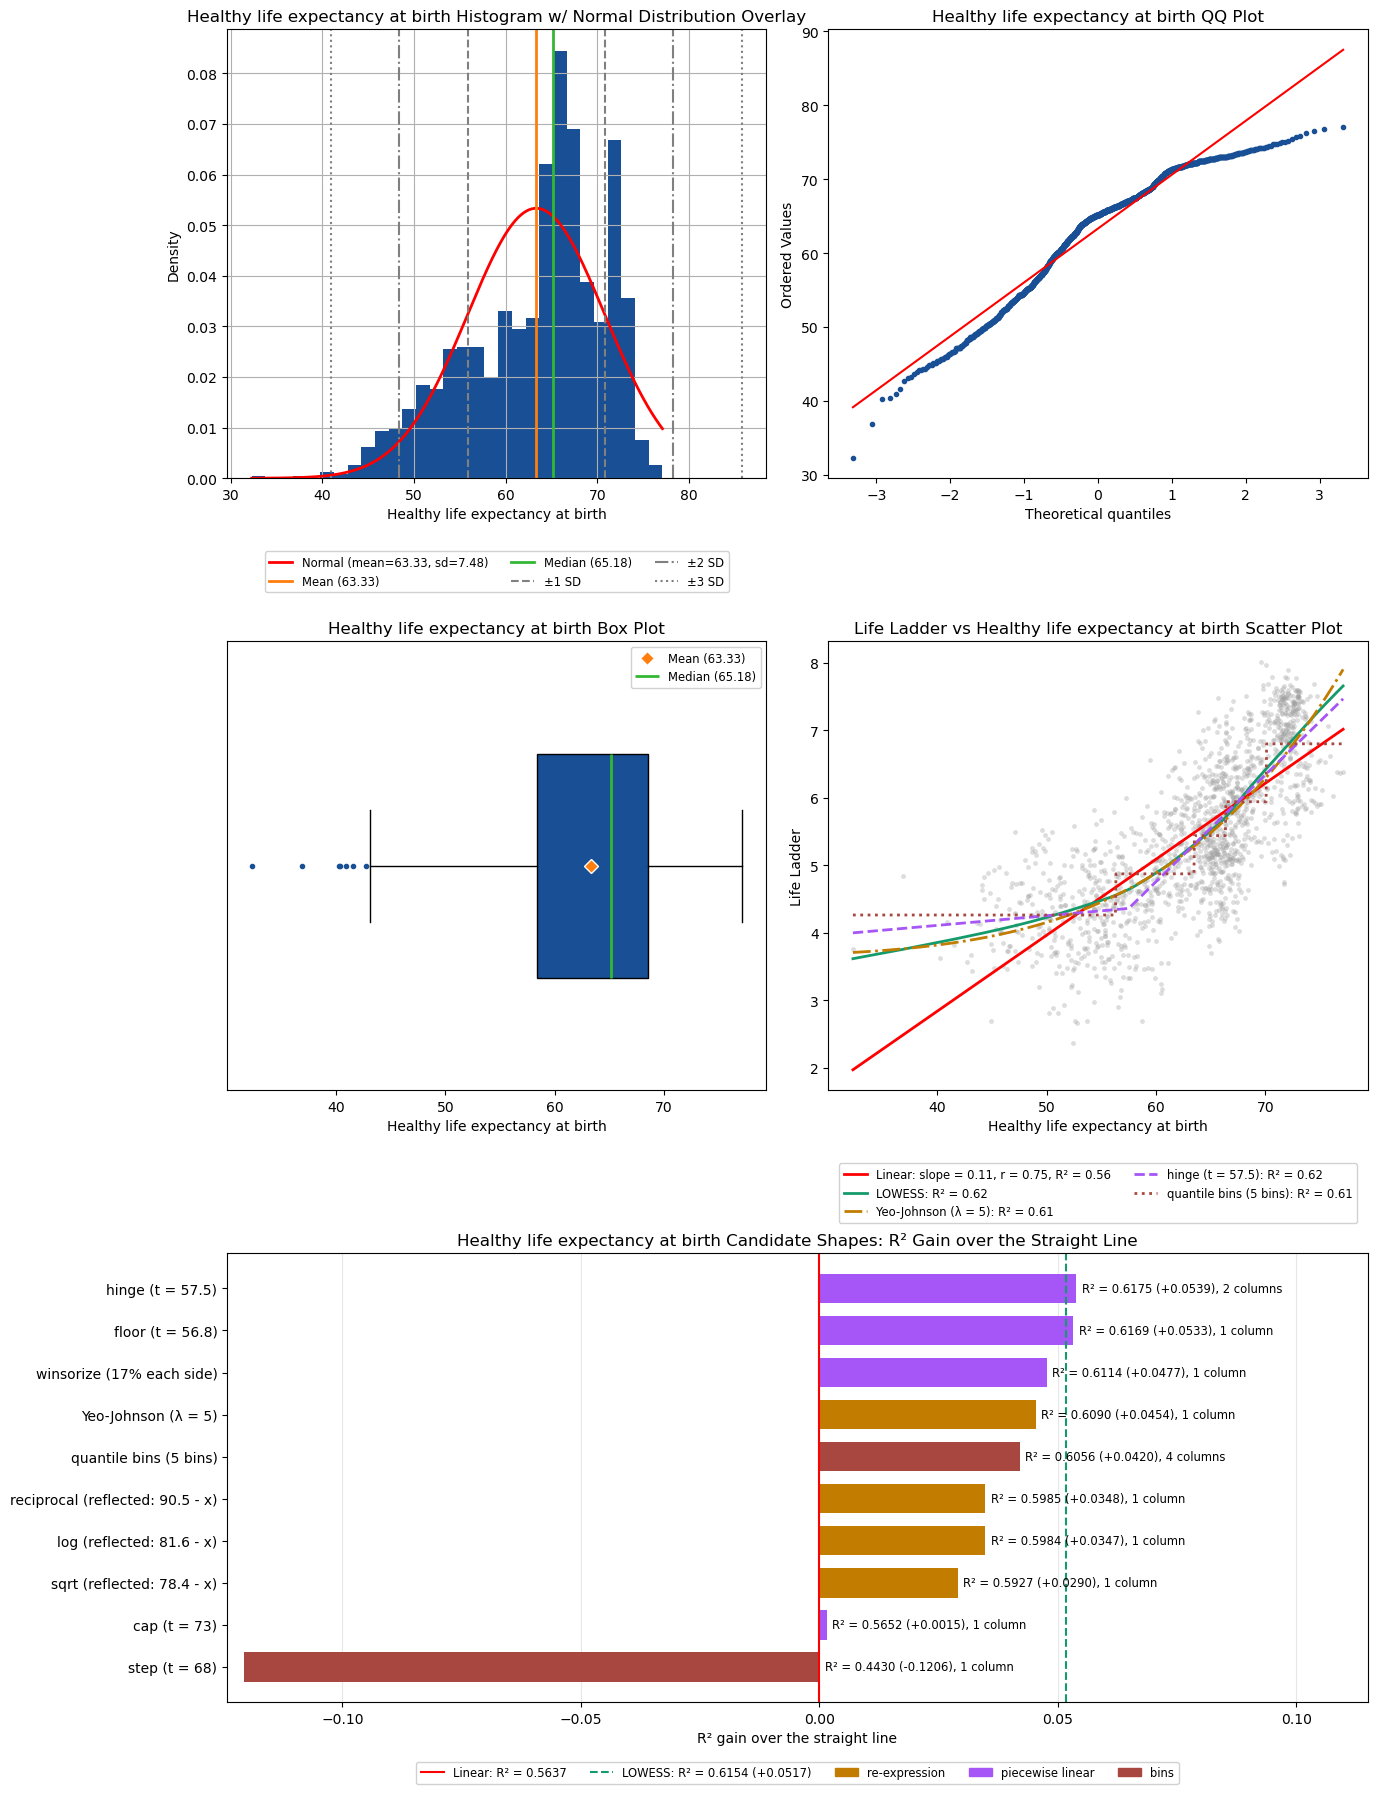

In [12]:
PLOTTING.continuous_single_feature_plots(df=train_df, feature=Q1_CONSTS.COLUMNS['HLEAB']['col'], target=Q1_CONSTS.TARGET);

## Notes / Observations

### Noticeable Traits / Key Attributes

- Shallow, then steep: LOWESS rises only slowly at the low end, while the straight line keeps its slope and predicts far too low there, which costs R² 0.56 against 0.62 for LOWESS.
- The bend is a corner: below it the attribute barely changes the prediction, so a one column floor fits as well as the two column hinge (R² 0.62 each).
- The 7 low IQR outliers sit on the flat part of LOWESS. They are off the straight line only because the line extends its slope into them.
- Large scale (std 7.478): unscaled, a penalty or gradient step treats this column very differently from a column near unit scale.

### Special Treatment

- **Feature engineering:** recommend a floor at t = 56.8 (`max(x, 56.8)`) or the hinge: the same gain (+0.05 each), both above LOWESS. Quantile bins also reach the 0.03 tier, with four columns. Avoid the step and the cap: a step drops the slope above the bend, and a cap flattens the top, where `Life Ladder` rises fastest.
- **Transformations:** recommend Yeo-Johnson or winsorize as the one column alternative (+0.05 each). The reflected reciprocal, log and sqrt also reach the 0.03 tier, but the piecewise family fits this corner better.
- **Scaling:** standardize: std 7.478.
- **Outliers:** keep the 7 low outliers, do not drop them: they sit on the flat part of LOWESS, and the floor already gives them the same value as the rest of that part.
- **Imputation:** fill the missing rows with the median: the left skew pulls the mean down (63.332 against the median 65.18).

# Negative Affect

In [13]:
STATISTICS.continuous_statistics_df(series=train_df[Q1_CONSTS.COLUMNS['NA']['col']], target=train_df[Q1_CONSTS.TARGET])

,Negative affect
count,1545
missing,14
% missing,0.898
mean,0.268
std,0.084
min,0.083
50%,0.258
max,0.705
range,0.622
skew,0.696


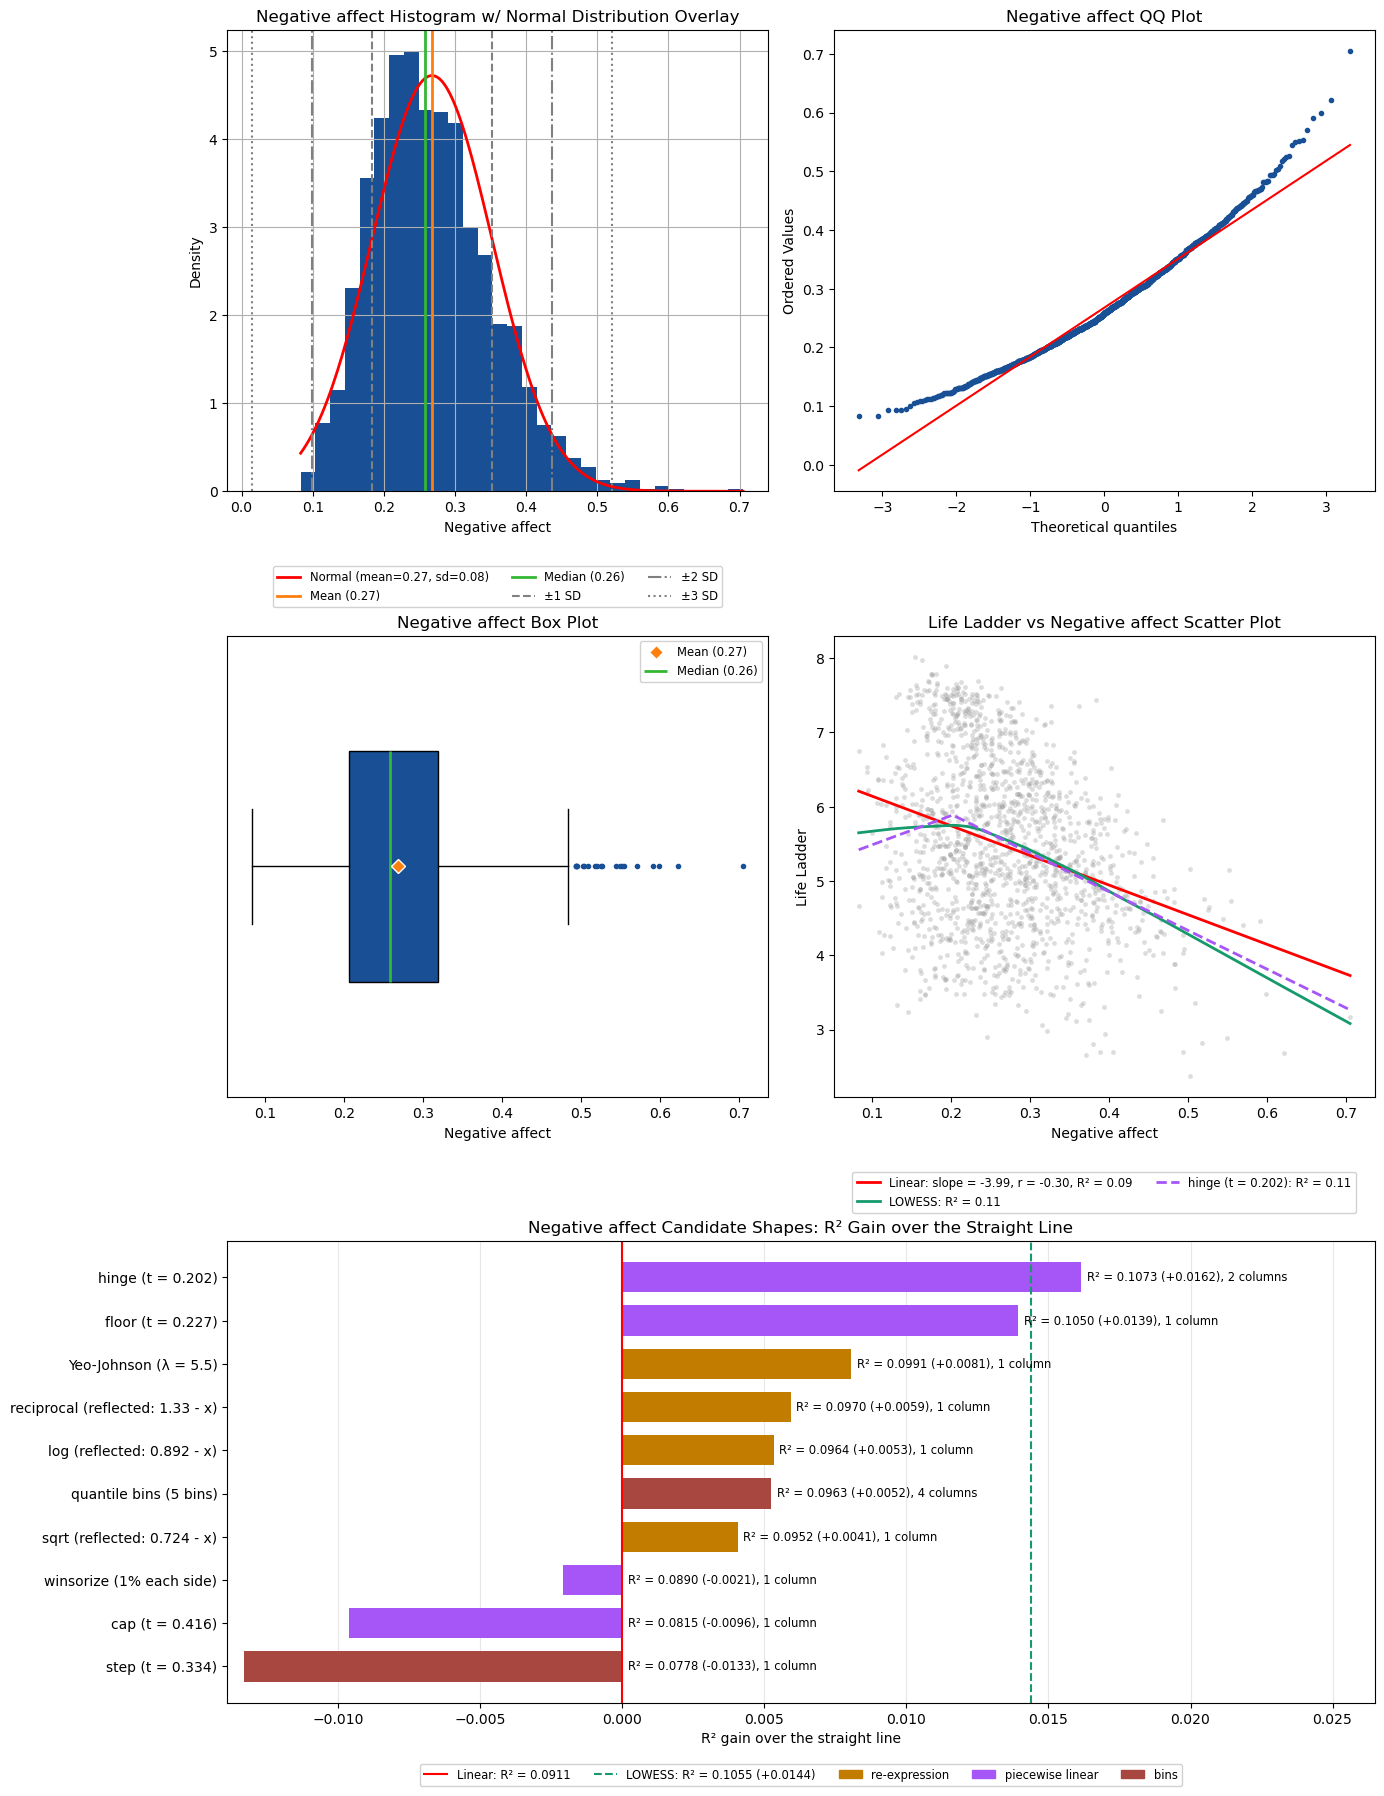

In [14]:
PLOTTING.continuous_single_feature_plots(df=train_df, feature=Q1_CONSTS.COLUMNS['NA']['col'], target=Q1_CONSTS.TARGET);

## Notes / Observations

### Noticeable Traits / Key Attributes

- Weak in any shape: linear R² 0.09, and even LOWESS only reaches 0.11, so this column can move the predictions only a little.
- Flat, then falling: LOWESS is level up to about 0.2, then falls to the max. The straight line over-predicts at both ends, and the hinge follows LOWESS.
- The 20 high IQR outliers sit on the falling part of LOWESS, so they follow the trend, and shapes that pull them in (cap, winsorize) lose R².
- The right skew points to log or sqrt, but every re-expression gains 0.01 or less: the skew does not bend the relationship with `Life Ladder`.

### Special Treatment

- **Dropping:** test the model without it: no shape lifts R² above 0.11.
- **Feature engineering:** if kept, the hinge at t = 0.202 is worth testing, small gain (+0.02). Avoid every other piecewise and bins shape, including a high negative affect flag (step), which loses R².
- **Transformations:** avoid the whole re-expression family and winsorize: none gains more than +0.01.
- **Outliers:** keep the 20 high outliers, do not clip or drop them: they sit on the falling part of LOWESS.
- **Imputation:** fill the missing rows with the median: the right skew pulls the mean up (0.268 against the median 0.258).

# Freedom to Make Life Choices

In [15]:
STATISTICS.continuous_statistics_df(series=train_df[Q1_CONSTS.COLUMNS['FTMLC']['col']], target=train_df[Q1_CONSTS.TARGET])

,Freedom to make life choices
count,1537
missing,22
% missing,1.411
mean,0.742
std,0.142
min,0.26
50%,0.763
max,0.985
range,0.725
skew,-0.606


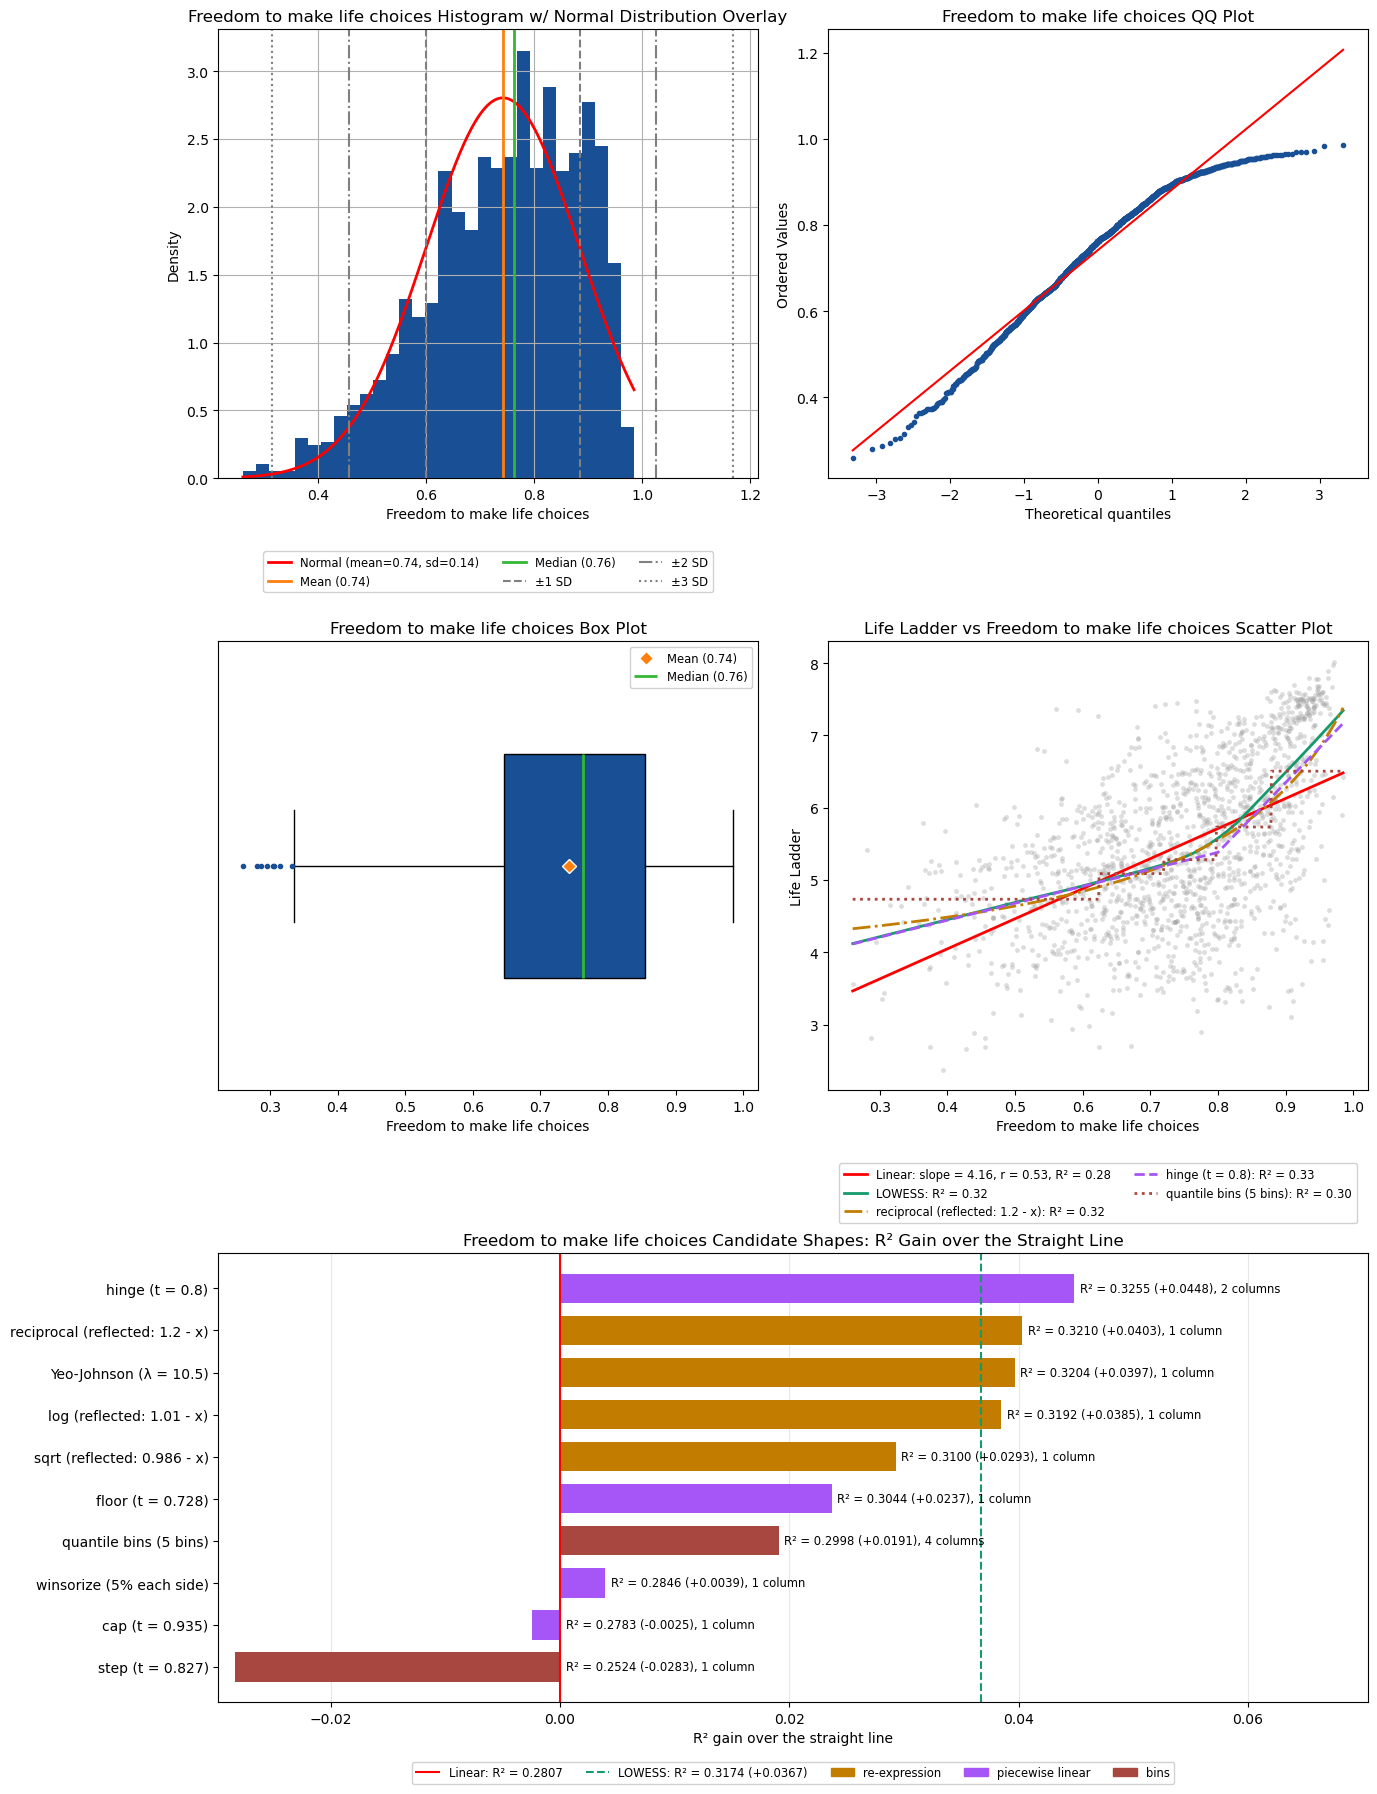

In [16]:
PLOTTING.continuous_single_feature_plots(df=train_df, feature=Q1_CONSTS.COLUMNS['FTMLC']['col'], target=Q1_CONSTS.TARGET);

## Notes / Observations

### Noticeable Traits / Key Attributes

- Shallow, then steep: LOWESS bends upward in the upper part of the range. The straight line under-predicts `Life Ladder` at both ends and over-predicts just below the bend, which costs R² 0.28 against 0.32 for LOWESS.
- The low side still rises, so it carries signal: the floor, which makes the low side flat, gains about half of what the hinge gains (+0.02 against +0.04).
- The bend is gradual enough that one column re-expressions that bend hardest at the top come close to the hinge (R² 0.32 for the reflected reciprocal, 0.33 for the hinge).
- The 8 low IQR outliers follow the straight low part of LOWESS, so they are on the trend.

### Special Treatment

- **Feature engineering:** recommend the hinge at t = 0.8, alongside the raw value (+0.04, the best shape, above LOWESS). The floor and quantile bins are worth testing, small gain. Avoid the step and the cap: both lose R².
- **Transformations:** recommend a re-expression that is steep at the high end as the one column alternative to the hinge: the reflected reciprocal, Yeo-Johnson or the reflected log (+0.04 each). The reflected sqrt also reaches the 0.03 tier. Avoid winsorize, which gains almost nothing.
- **Outliers:** keep the 8 low outliers, do not clip them: LOWESS rises through the low end at a steady rate.
- **Imputation:** fill the missing rows with the median: the left skew pulls the mean down (0.742 against the median 0.763).

# Positive Affect

In [17]:
STATISTICS.continuous_statistics_df(series=train_df[Q1_CONSTS.COLUMNS['PA']['col']], target=train_df[Q1_CONSTS.TARGET])

,Positive affect
count,1542
missing,17
% missing,1.09
mean,0.709
std,0.108
min,0.322
50%,0.721
max,0.944
range,0.622
skew,-0.348


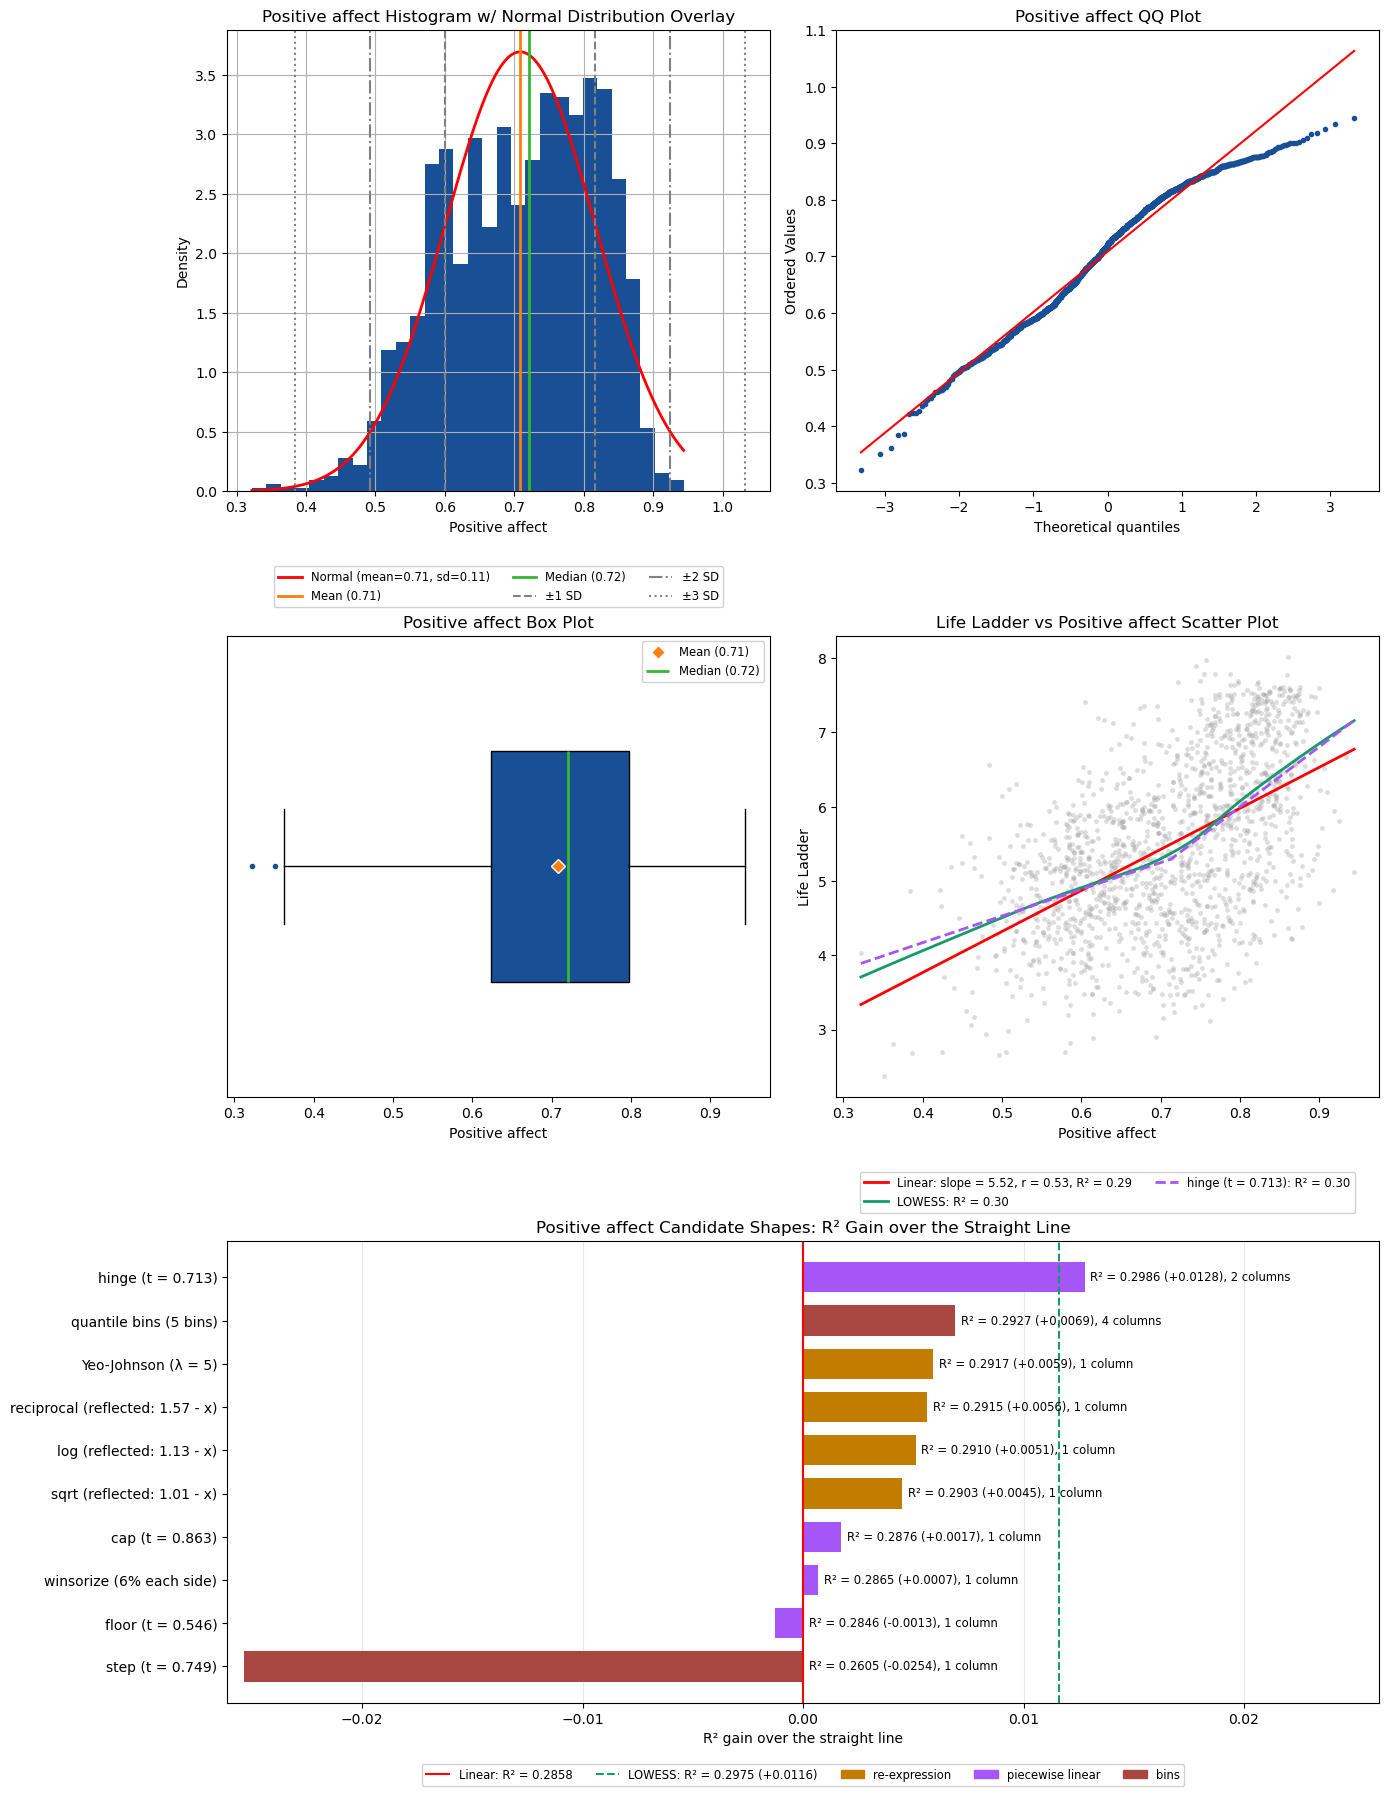

In [18]:
PLOTTING.continuous_single_feature_plots(df=train_df, feature=Q1_CONSTS.COLUMNS['PA']['col'], target=Q1_CONSTS.TARGET);

## Notes / Observations

### Noticeable Traits / Key Attributes

- Already close to a straight line: even LOWESS beats it by only 0.01 in R², so no shape has room to change the predictions.
- Cutting the column into levels throws away a slope that holds across the whole range: the 0 / 1 step loses R² (-0.03).

### Special Treatment

- **Feature engineering:** keep the raw value and avoid every piecewise and bins shape: the best, the hinge, gains only +0.01.
- **Transformations:** avoid the whole re-expression family and winsorize: none gains more than +0.01.
- **Imputation:** fill the missing rows with the mean or the median: the distribution is roughly symmetric, so the two are close (0.709 against 0.721).

# Log GDP per Capita

In [19]:
STATISTICS.continuous_statistics_df(series=train_df[Q1_CONSTS.COLUMNS['LGDP']['col']], target=train_df[Q1_CONSTS.TARGET])

,Log GDP per capita
count,1533
missing,26
% missing,1.668
mean,9.363
std,1.16
min,6.635
50%,9.456
max,11.648
range,5.013
skew,-0.292


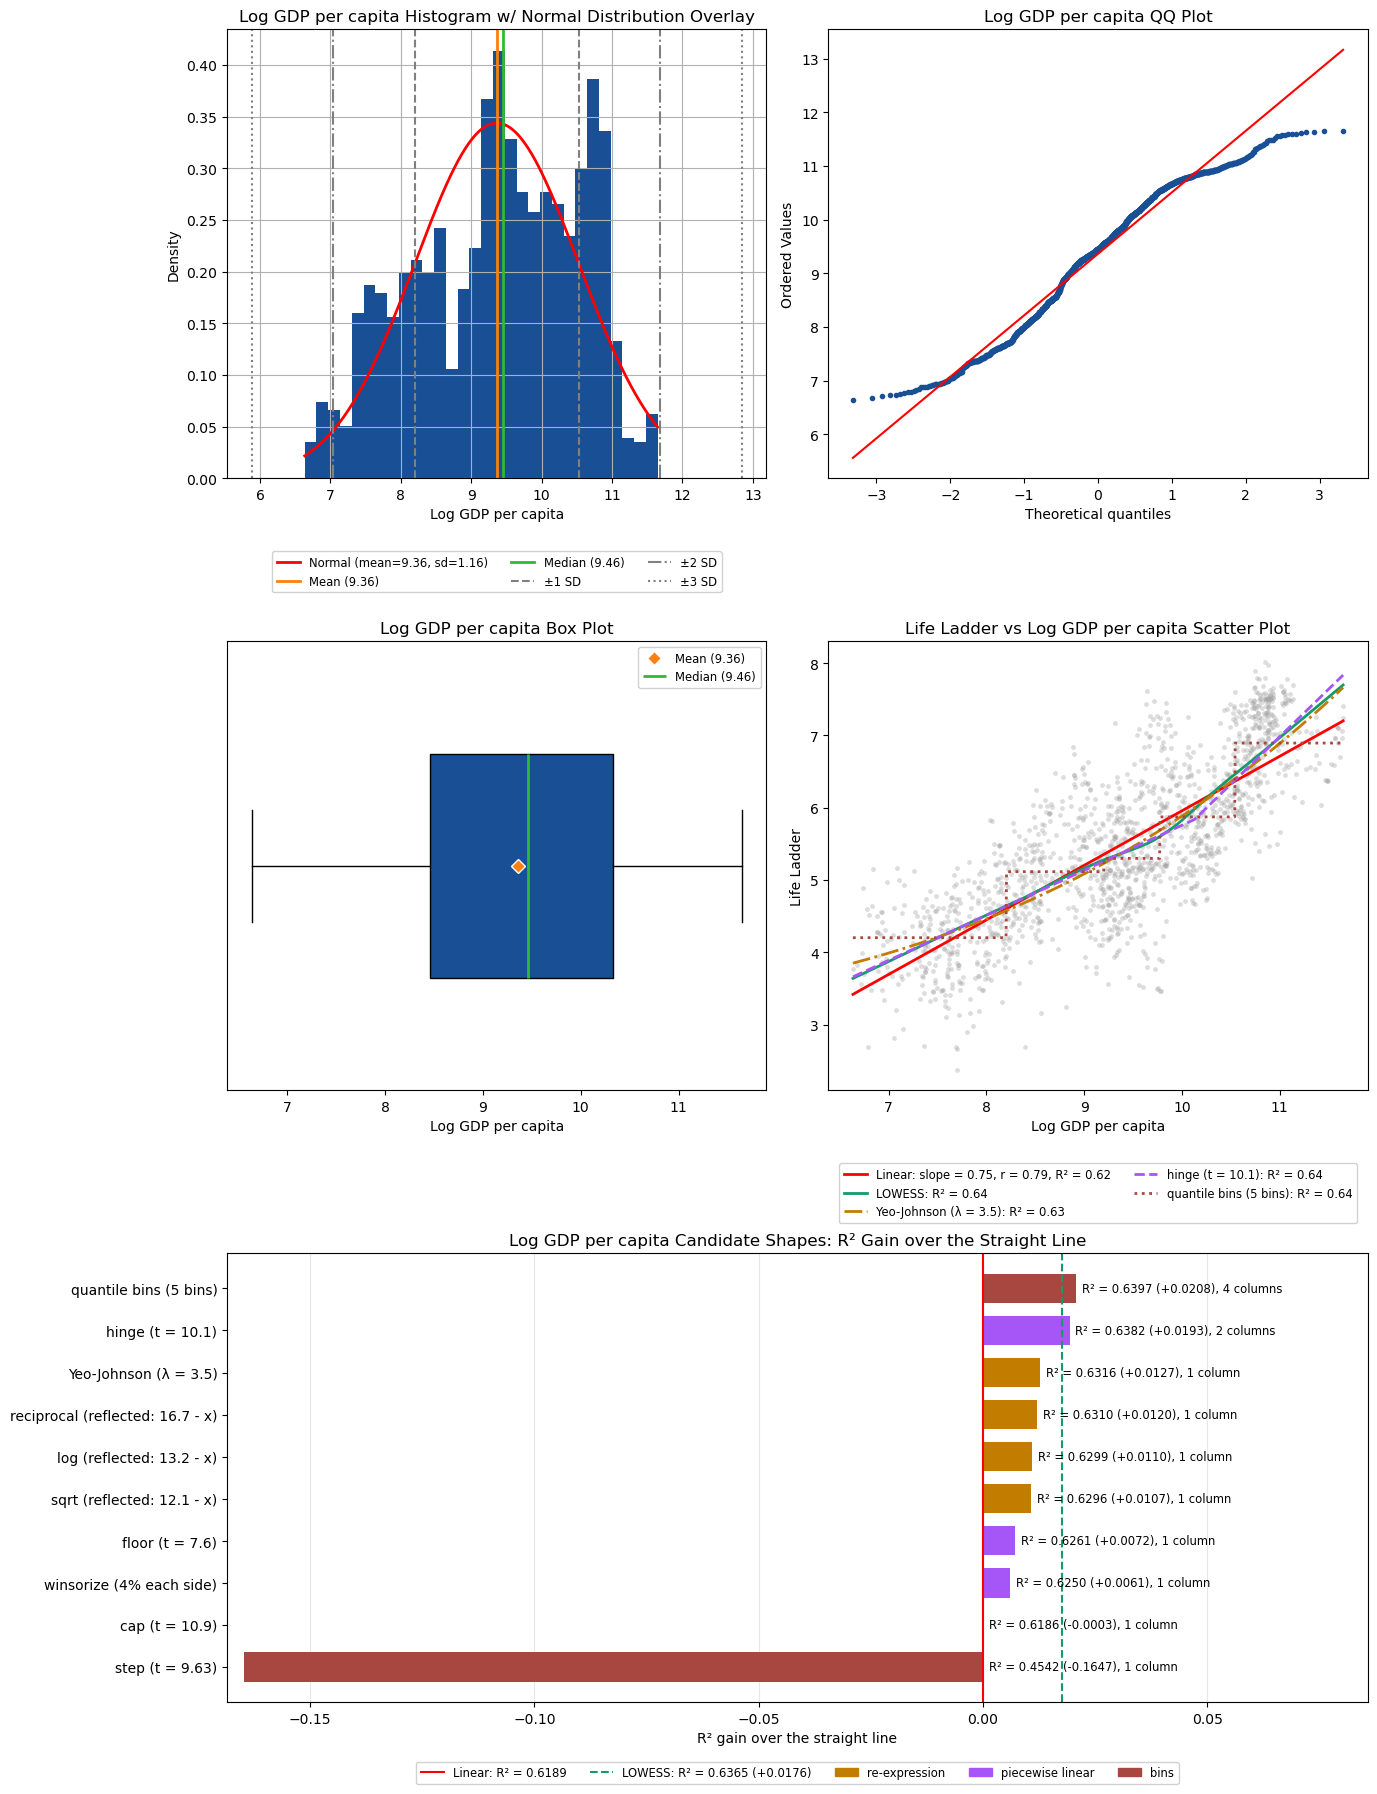

In [20]:
PLOTTING.continuous_single_feature_plots(df=train_df, feature=Q1_CONSTS.COLUMNS['LGDP']['col'], target=Q1_CONSTS.TARGET);

## Notes / Observations

### Noticeable Traits / Key Attributes

- Already close to a straight line: LOWESS beats it by only 0.02 in R², so a shape can add little.
- The slope steepens above about 10: the straight line under-predicts the top end, and the hinge and quantile bins follow that bend.
- Roughly symmetric with no IQR outliers, so there is nothing to clip and the fill value matters little.

### Special Treatment

- **Feature engineering:** the hinge at t = 10.1 and quantile bins are worth testing, small gain (+0.02 each). Prefer the hinge: the same gain with two columns instead of four. Avoid the step, the cap and the floor: the step alone loses R² heavily.
- **Transformations:** avoid the whole re-expression family and winsorize: none gains more than +0.01.
- **Scaling:** standardize: std 1.16.
- **Imputation:** fill the missing rows with the mean or the median: the distribution is roughly symmetric, so the two are close (9.363 against 9.456).